# Artemis II · 01 · Inventario y primera figura
**Fuente:** NASA PDS, bundle `artemis2_mission` (DOI 10.17189/36fx-pd80).
Guía de datos: Artemis II Lunar Science Data User Guide v1.0 (DOI 10.17189/dtpt-2857).

**Qué hace este notebook**
1. Carga los dos registros de temperatura y humedad de Orion (HOBO).
2. Comprueba la calidad de los datos y convierte la hora de CDT a UTC.
3. Dibuja la primera figura, con los hitos de la misión.
4. Carga el *Outgoing Target Request* (OTR) y cuenta a qué objetivos de la matriz de trazabilidad (STM) apunta cada observación.

## 1. Subir los archivos (solo en Colab)
Ejecuta la celda y selecciona los **3 archivos** (2 CSV HOBO + el JSON del OTR).

In [1]:
from google.colab import files
subidos = files.upload()

Saving art002_086-162546_111-205046_hobo1104_raw_v01.csv to art002_086-162546_111-205046_hobo1104_raw_v01.csv
Saving art002_086-162926_111-203826_hobo1105_raw_v01.csv to art002_086-162926_111-203826_hobo1105_raw_v01.csv
Saving artemis2_outgoing_target_request.json to artemis2_outgoing_target_request.json


## 2. Librerías y localización de archivos

In [2]:
import glob, json
import pandas as pd
import matplotlib.pyplot as plt

print("pandas", pd.__version__)

rutas_hobo = sorted(glob.glob("*hobo*_raw_v01.csv"))
ruta_otr = "artemis2_outgoing_target_request.json"
print("CSV HOBO encontrados:", rutas_hobo)

pandas 2.2.3
CSV HOBO encontrados: ['art002_086-162546_111-205046_hobo1104_raw_v01.csv', 'art002_086-162926_111-203826_hobo1105_raw_v01.csv']


## 3. Cargar los HOBO
La hora original viene en **CDT** (hora de verano del centro de EE. UU., UTC−5).
La convertimos a **UTC** para poder compararla con los hitos de la misión.
Esta conversión es coherente con los nombres de archivo, que indican el rango en UTC.

In [3]:
def cargar_hobo(ruta):
    d = pd.read_csv(ruta)
    d.columns = ["n", "hora_cdt", "temp_c", "hr_pct", "rocio_c"]
    d["hora_cdt"] = pd.to_datetime(d["hora_cdt"], format="%m/%d/%Y %H:%M:%S")
    d["hora_utc"] = d["hora_cdt"] + pd.Timedelta(hours=5)
    d["logger"] = "hobo" + ruta.split("hobo")[1][:4]
    return d

hobo = pd.concat([cargar_hobo(r) for r in rutas_hobo], ignore_index=True)
hobo.head()

,n,hora_cdt,temp_c,hr_pct,rocio_c,hora_utc,logger
0,1,2026-03-26 11:25:46,21.13,28.253,2.05,2026-03-26 16:25:46,hobo1104
1,2,2026-03-26 11:26:46,21.13,28.253,2.05,2026-03-26 16:26:46,hobo1104
2,3,2026-03-26 11:27:46,21.13,28.253,2.05,2026-03-26 16:27:46,hobo1104
3,4,2026-03-26 11:28:46,21.15,28.253,2.07,2026-03-26 16:28:46,hobo1104
4,5,2026-03-26 11:29:46,21.13,28.308,2.08,2026-03-26 16:29:46,hobo1104


## 4. Control de calidad

In [4]:
for nombre, g in hobo.groupby("logger"):
    pasos = g["hora_utc"].diff().dropna()
    print(nombre)
    print("  filas:", len(g))
    print("  desde:", g["hora_utc"].min(), " hasta:", g["hora_utc"].max())
    print("  huecos > 2 min:", (pasos > pd.Timedelta(minutes=2)).sum())
    print("  valores nulos:", int(g.isna().sum().sum()))
    print()

hobo.groupby("logger")[["temp_c", "hr_pct", "rocio_c"]].describe().round(2).T

hobo1104
  filas: 37706
  desde: 2026-03-26 16:25:46  hasta: 2026-04-21 20:50:46
  huecos > 2 min: 0
  valores nulos: 0

hobo1105
  filas: 37690
  desde: 2026-03-26 16:29:26  hasta: 2026-04-21 20:38:26
  huecos > 2 min: 0
  valores nulos: 0



logger         hobo1104  hobo1105
temp_c  count  37706.00  37690.00
        mean      22.06     21.81
        std        1.75      1.46
        min       17.77     16.82
        25%       21.01     21.03
        50%       21.44     21.34
        75%       23.47     22.61
        max       25.57     27.11
hr_pct  count  37706.00  37690.00
        mean      38.51     35.54
        std       16.26     11.61
        min       18.27     18.69
        25%       24.62     26.75
        50%       27.61     27.89
        75%       57.37     49.80
        max       68.58     78.14
rocio_c count  37706.00  37690.00
        mean       6.10      5.23
        std        5.32      4.46
        min       -2.87     -1.82
        25%        1.67      1.66
        50%        2.99      3.19
        75%       12.24     10.18
        max       15.56     17.09

## 5. Primera figura: temperatura y humedad de Orion
Hitos usados (todos en UTC, según la guía de datos):
- Lanzamiento: 2026-04-01 22:35:12
- Amerizaje: 2026-04-11 00:07:00
- Ventana de observación lunar: 6 abr 18:00 a 7 abr 02:00 (según el OTR; **se asume UTC**, a verificar)

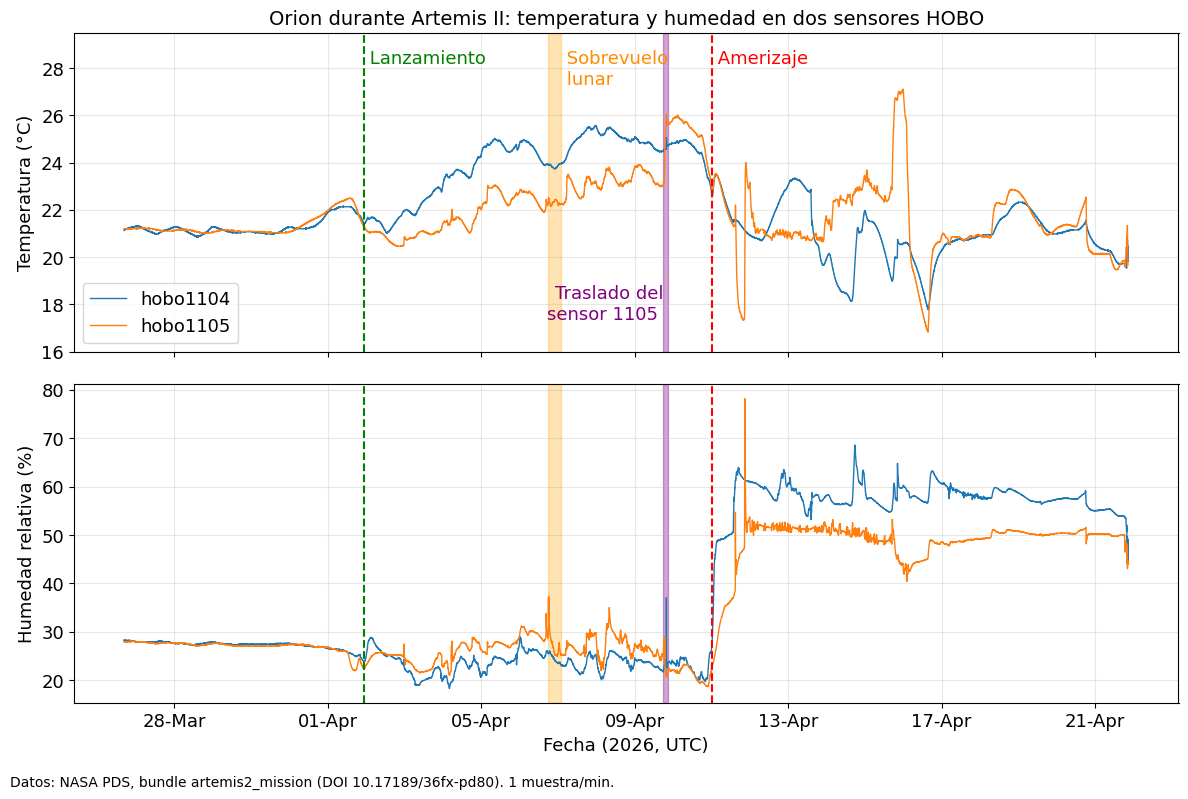

In [5]:
import matplotlib.dates as mdates
plt.rcParams.update({"font.size": 13})

lanzamiento = pd.Timestamp("2026-04-01 22:35:12")
amerizaje   = pd.Timestamp("2026-04-11 00:07:00")
sobrevuelo  = (pd.Timestamp("2026-04-06 18:00"), pd.Timestamp("2026-04-07 02:00"))
traslado    = (pd.Timestamp("2026-04-09 18:00"), pd.Timestamp("2026-04-09 21:00"))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for nombre, g in hobo.groupby("logger"):
    ax1.plot(g["hora_utc"], g["temp_c"], linewidth=1, label=nombre)
    ax2.plot(g["hora_utc"], g["hr_pct"], linewidth=1, label=nombre)

for ax in (ax1, ax2):
    ax.axvspan(*traslado, color="purple", alpha=0.35)
    ax.axvline(lanzamiento, color="green", linestyle="--")
    ax.axvline(amerizaje, color="red", linestyle="--")
    ax.axvspan(*sobrevuelo, color="orange", alpha=0.3)
    ax.grid(alpha=0.3)

ax1.set_ylim(16, 29.5)
ax1.set_ylabel("Temperatura (°C)")
ax2.set_ylabel("Humedad relativa (%)")
ax1.legend(loc="lower left")
ax1.text(traslado[0], 17.2, "Traslado del\nsensor 1105 ", color="purple", va="bottom", ha="right")
ax1.text(lanzamiento, 28.8, " Lanzamiento", color="green", va="top")
ax1.text(amerizaje, 28.8, " Amerizaje", color="red", va="top")
ax1.text(sobrevuelo[1], 28.8, " Sobrevuelo\n lunar", color="darkorange", va="top", ha="left")

ax2.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax2.set_xlabel("Fecha (2026, UTC)")
ax1.set_title("Orion durante Artemis II: temperatura y humedad en dos sensores HOBO", fontsize=14)
fig.text(0.01, 0.005, "Datos: NASA PDS, bundle artemis2_mission (DOI 10.17189/36fx-pd80). 1 muestra/min.", fontsize=10)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig("fig01_hobo_mision.png", dpi=150)
plt.show()

## 6. Medias diarias
Tabla de apoyo para describir lo que se ve en la figura. Mira cómo cambian los valores antes del lanzamiento, durante el vuelo y tras el amerizaje.

In [6]:
diario = (hobo.set_index("hora_utc")
              .groupby("logger")[["temp_c", "hr_pct"]]
              .resample("D").mean().round(1))
diario.unstack(0)

temp_c            hr_pct         
logger     hobo1104 hobo1105 hobo1104 hobo1105
hora_utc                                      
2026-03-26     21.2     21.2     28.2     28.0
2026-03-27     21.1     21.2     27.9     27.7
2026-03-28     21.1     21.1     27.6     27.4
2026-03-29     21.1     21.1     27.5     27.3
2026-03-30     21.1     21.1     27.5     27.1
2026-03-31     21.3     21.5     27.1     27.1
2026-04-01     22.0     22.1     25.6     24.8
2026-04-02     21.5     20.8     25.7     25.2
2026-04-03     22.4     21.0     20.8     23.0
2026-04-04     23.6     21.5     22.4     26.1
2026-04-05     24.7     22.6     23.8     27.2
2026-04-06     24.3     22.4     25.7     29.2
2026-04-07     24.9     22.9     23.4     27.0
2026-04-08     25.2     23.3     23.8     27.7
2026-04-09     24.7     23.9     23.4     25.2
2026-04-10     24.5     25.2     22.5     21.2
2026-04-11     22.0     21.5     53.2     38.6
2026-04-12     21.5     21.1     59.9     51.7
2026-04-13     22.0     20.9     57.7     51.3
2026-04-14     19.5     22.4     58.6     50.8
2026-04-15     20.6     23.9     57.2     48.3
2026-04-16     19.5     20.0     59.2     45.4
2026-04-17     20.7     20.8     58.9     48.7
2026-04-18     21.5     21.9     58.7     50.3
2026-04-19     21.6     21.6     57.2     50.2
2026-04-20     21.1     21.2     57.1     50.4
2026-04-21     20.1     20.0     54.2     49.7

## 7. Outgoing Target Request (OTR)
Es la lista de objetivos que el equipo científico pidió observar durante el sobrevuelo.
Cada entrada trae campos `stm1` a `stm10` (verdadero/falso): a qué objetivos de la *Science Traceability Matrix* contribuye.
**Qué significa cada STM** no viene en el JSON: hay que buscarlo en el *Preliminary Lunar Science Report* o en el OSDMP.

In [7]:
with open(ruta_otr, encoding="utf-8") as f:
    crudo = json.load(f)

otr = pd.DataFrame([e["target_properties"] for e in crudo])

# Dos formatos de fecha distintos en el mismo campo
otr["inicio"] = pd.to_datetime(otr["start_date_time"], format="mixed", errors="coerce")
otr["fin"]    = pd.to_datetime(otr["end_date_time"],   format="mixed", errors="coerce")

stm_cols = [c for c in otr.columns if c.startswith("stm")]
otr["n_stm"] = otr[stm_cols].sum(axis=1)

# 'order' mezcla números (objetivos) y letras (logística: cambios de posición/equipo)
otr["tipo"] = otr["order"].astype(str).str.isalpha().map({True: "logística", False: "observación"})

print("Entradas totales:", len(otr))
print(otr["tipo"].value_counts().to_string())
print("Observaciones sin ningún STM:", int(((otr["tipo"] == "observación") & (otr["n_stm"] == 0)).sum()))
print("Entradas sin fecha de inicio:", int(otr["inicio"].isna().sum()))
otr[["order", "target_name", "inicio", "fin", "request_duration", "time_sensitive", "n_stm", "tipo"]]

Entradas totales: 39
tipo
observación    30
logística       9
Observaciones sin ningún STM: 14
Entradas sin fecha de inicio: 6


,order,target_name,inicio,fin,request_duration,time_sensitive,n_stm,tipo
0,1,Guided Discussion,2026-04-06 18:00:00.000000,2026-04-07 02:00:00.000000,10,False,0,observación
1,2,Guided Discussion,2026-04-06 18:00:00.000000,2026-04-07 02:00:00.000000,20,False,0,observación
2,3,Glushko Crater,2026-04-06 18:00:00.000000,2026-04-06 22:20:40.935000,8,True,5,observación
3,4,Ohm Crater,2026-04-06 18:00:00.000000,2026-04-06 23:21:52.324000,8,False,4,observación
4,a,Crew Position Swap,2026-04-06 18:00:00.000000,2026-04-07 02:00:00.000000,2,False,0,logística
5,5,Aristarchus Plateau,2026-04-06 18:00:00.000000,2026-04-06 21:32:50.700000,11,False,6,observación
6,6,Reiner Gamma,2026-04-06 18:00:00.000000,2026-04-06 21:55:37.199000,8,False,5,observación
7,b,Crew Team Swap,2026-04-06 19:50:00.000000,2026-04-06 20:05:00.000000,15,False,0,logística
8,7,Whole Moon,NaT,NaT,10,False,1,observación
9,8,Orientale Basin,2026-04-06 18:00:00.000000,2026-04-06 23:34:17.065000,16,False,7,observación


## 8. ¿Cuántos objetivos tocan cada STM?

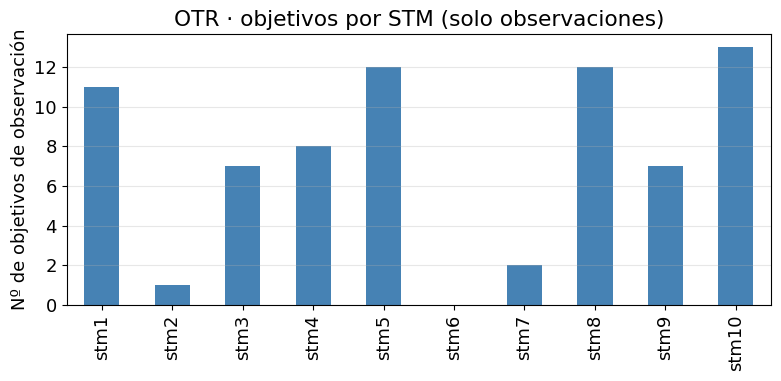

,0
stm1,11
stm2,1
stm3,7
stm4,8
stm5,12
stm6,0
stm7,2
stm8,12
stm9,7
stm10,13


In [8]:
obs = otr[otr["tipo"] == "observación"]
conteo = obs[stm_cols].sum()

ax = conteo.plot(kind="bar", figsize=(8, 4), color="steelblue")
ax.set_ylabel("Nº de objetivos de observación")
ax.set_title("OTR · objetivos por STM (solo observaciones)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("fig02_otr_stm.png", dpi=150)
plt.show()

conteo

## 9. Descargar las figuras (solo en Colab)

In [9]:
from google.colab import files
files.download("fig01_hobo_mision.png")
files.download("fig02_otr_stm.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>